# Visual pseudocode of the four implemented generators

This notebook converts the generator pseudocodes into four comparable images. Black boxes and arrows belong to the original AST workflow. Red boxes and arrows identify additions or replacements made by a proposed generator. The detailed textual versions are available for the [original AST](PSEUDOCODE.md), [coefficient-gated AST](stability_mitigation/PSEUDOCODE.md), [stationary generator](stationarity_by_construction/PSEUDOCODE.md), and [contraction-certified AST](contraction_by_construction/PSEUDOCODE.md).

The diagrams describe the implementation currently present under `src/tsfmxai/generators/`; they are not generic diagrams for every possible generator in each mathematical family.

In [1]:
from __future__ import annotations

import importlib.metadata
import json
from pathlib import Path
import platform
import subprocess
import sys
import textwrap

from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Patch

BLACK = '#232323'
GRAY = '#667085'
SHARED_FILL = '#f4f6f8'
RED = '#c62828'
RED_FILL = '#ffebee'
BOX_WIDTH = 2.55
BOX_HEIGHT = 1.08


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'pyproject.toml').exists():
            return candidate
    raise RuntimeError('Repository root not found.')


PROJECT_ROOT = find_project_root(Path.cwd().resolve())


def _edge_points(start, end, width=BOX_WIDTH, height=BOX_HEIGHT):
    sx, sy = start
    ex, ey = end
    dx, dy = ex - sx, ey - sy
    if abs(dx) >= abs(dy):
        direction = 1 if dx >= 0 else -1
        return (sx + direction * width / 2, sy), (ex - direction * width / 2, ey)
    direction = 1 if dy >= 0 else -1
    return (sx, sy + direction * height / 2), (ex, ey - direction * height / 2)


def render_flowchart(title, subtitle, steps, edges):
    fig, ax = plt.subplots(figsize=(16, 7.6), dpi=130)
    ax.set_xlim(0, 16)
    ax.set_ylim(0, 8)
    ax.axis('off')
    ax.text(0.35, 7.55, title, fontsize=20, fontweight='bold', color=BLACK, va='top')
    ax.text(0.35, 7.03, subtitle, fontsize=11.2, color=GRAY, va='top')

    by_name = {step['name']: step for step in steps}
    for edge in edges:
        source = by_name[edge[0]]
        target = by_name[edge[1]]
        start, end = _edge_points(source['position'], target['position'])
        changed = edge[2] if len(edge) > 2 else target.get('changed', False)
        arrow = FancyArrowPatch(
            start, end, arrowstyle='-|>', mutation_scale=17, linewidth=2.2,
            color=RED if changed else GRAY, connectionstyle='arc3,rad=0.0',
            zorder=1,
        )
        ax.add_patch(arrow)

    for step in steps:
        changed = step.get('changed', False)
        x, y = step['position']
        box = FancyBboxPatch(
            (x - BOX_WIDTH / 2, y - BOX_HEIGHT / 2), BOX_WIDTH, BOX_HEIGHT,
            boxstyle='round,pad=0.08,rounding_size=0.09',
            linewidth=2.3 if changed else 1.7,
            edgecolor=RED if changed else BLACK,
            facecolor=RED_FILL if changed else SHARED_FILL,
            zorder=2,
        )
        ax.add_patch(box)
        label = textwrap.fill(step['label'], width=27, break_long_words=False)
        ax.text(
            x, y, label, ha='center', va='center', fontsize=10.2,
            color=RED if changed else BLACK,
            fontweight='bold' if changed else 'normal', zorder=3,
        )

    ax.legend(
        handles=[
            Patch(facecolor=SHARED_FILL, edgecolor=BLACK, label='Inherited from original AST'),
            Patch(facecolor=RED_FILL, edgecolor=RED, linewidth=2,
                  label='Difference relative to original AST'),
        ],
        loc='lower center', bbox_to_anchor=(0.5, -0.01), ncol=2,
        frameon=False, fontsize=10.5,
    )
    fig.tight_layout()
    return fig


**What this cell does.** It defines a deterministic drawing function shared by all four images. The color convention is fixed once so that the comparisons use the same visual meaning.

## 1. Original random AST generator

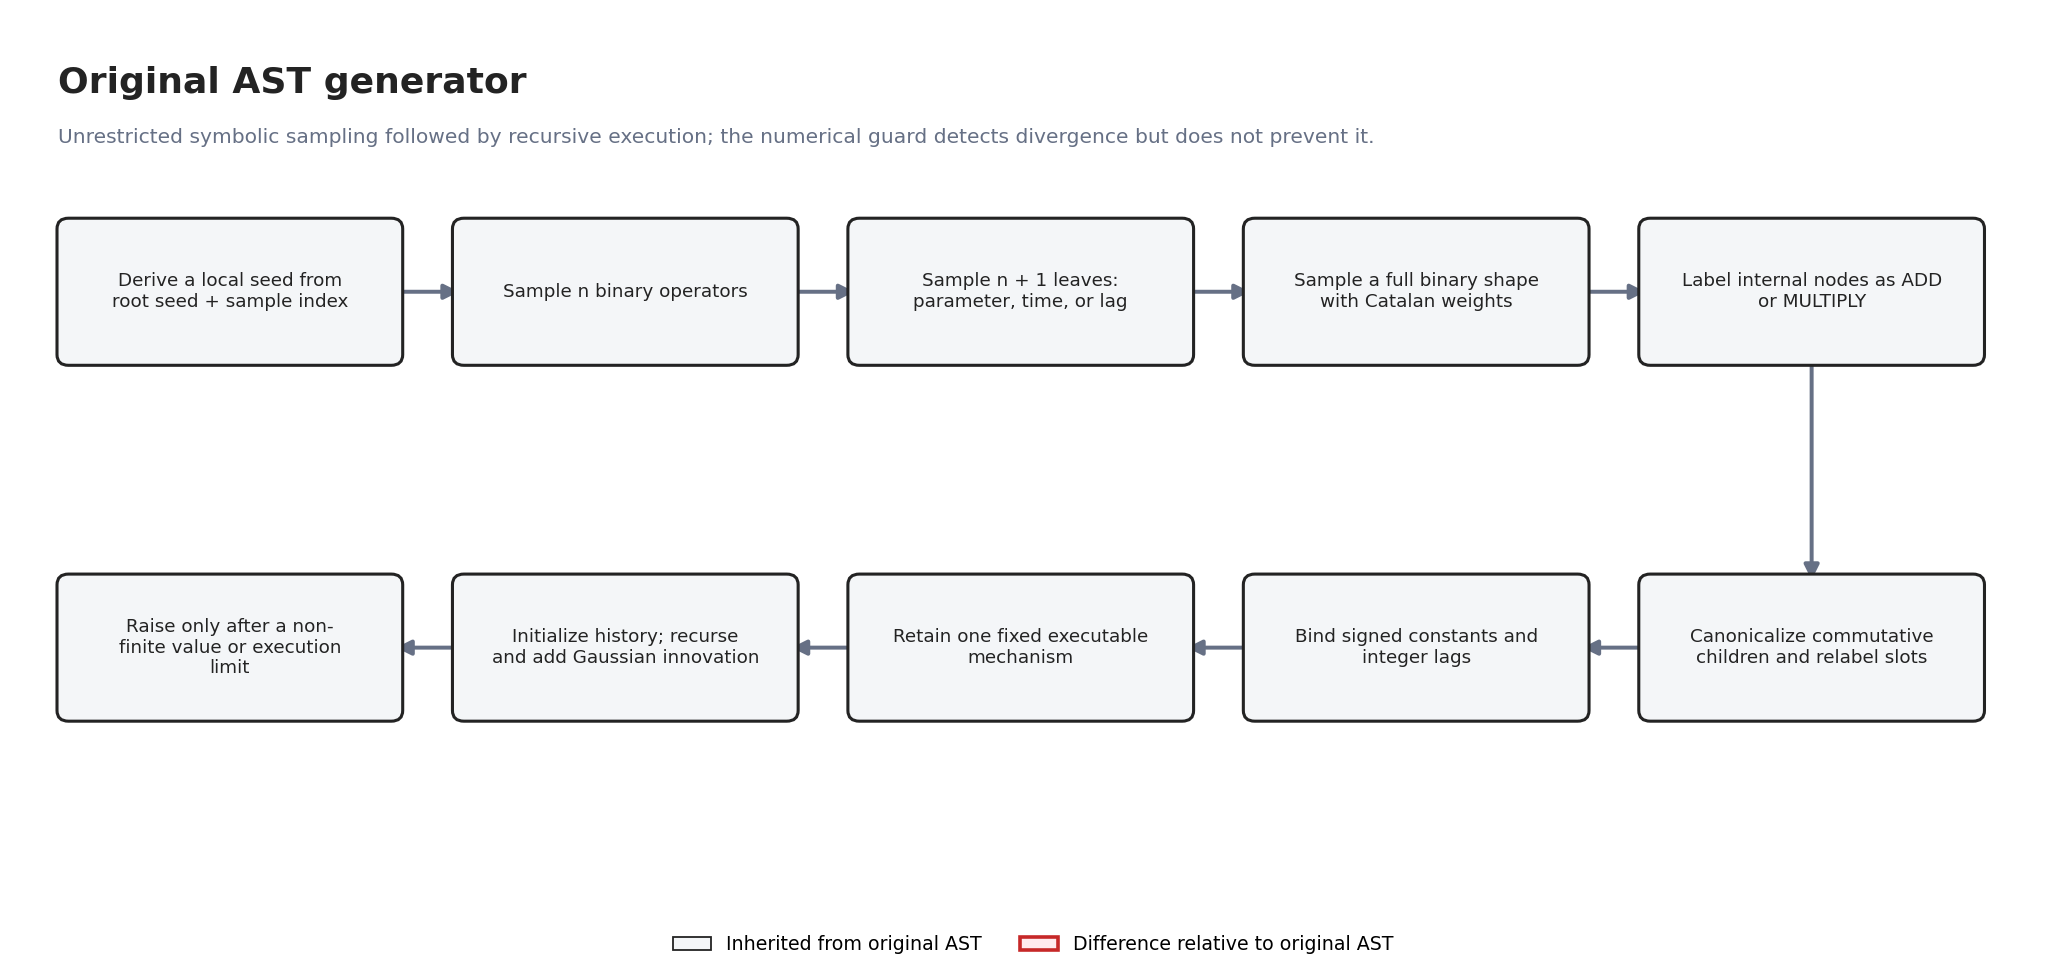

In [2]:
original_steps = [
    {'name': 'seed', 'label': 'Derive a local seed from root seed + sample index', 'position': (1.7, 5.65)},
    {'name': 'size', 'label': 'Sample n binary operators', 'position': (4.8, 5.65)},
    {'name': 'leaves', 'label': 'Sample n + 1 leaves: parameter, time, or lag', 'position': (7.9, 5.65)},
    {'name': 'shape', 'label': 'Sample a full binary shape with Catalan weights', 'position': (11.0, 5.65)},
    {'name': 'ops', 'label': 'Label internal nodes as ADD or MULTIPLY', 'position': (14.1, 5.65)},
    {'name': 'canonical', 'label': 'Canonicalize commutative children and relabel slots', 'position': (14.1, 2.65)},
    {'name': 'bind', 'label': 'Bind signed constants and integer lags', 'position': (11.0, 2.65)},
    {'name': 'mechanism', 'label': 'Retain one fixed executable mechanism', 'position': (7.9, 2.65)},
    {'name': 'trajectory', 'label': 'Initialize history; recurse and add Gaussian innovation', 'position': (4.8, 2.65)},
    {'name': 'guard', 'label': 'Raise only after a non-finite value or execution limit', 'position': (1.7, 2.65)},
]
original_edges = [
    ('seed', 'size'), ('size', 'leaves'), ('leaves', 'shape'), ('shape', 'ops'),
    ('ops', 'canonical'), ('canonical', 'bind'), ('bind', 'mechanism'),
    ('mechanism', 'trajectory'), ('trajectory', 'guard'),
]
fig = render_flowchart(
    'Original AST generator',
    'Unrestricted symbolic sampling followed by recursive execution; the numerical guard detects divergence but does not prevent it.',
    original_steps, original_edges,
)
display(fig)
plt.close(fig)


**What this image shows.** The original generator independently samples tree structure, operators, terminal types, coefficients, and lags. Stability is not part of mechanism sampling; the final guard only stops an already divergent execution.

## 2. AST with coefficient-gated lags

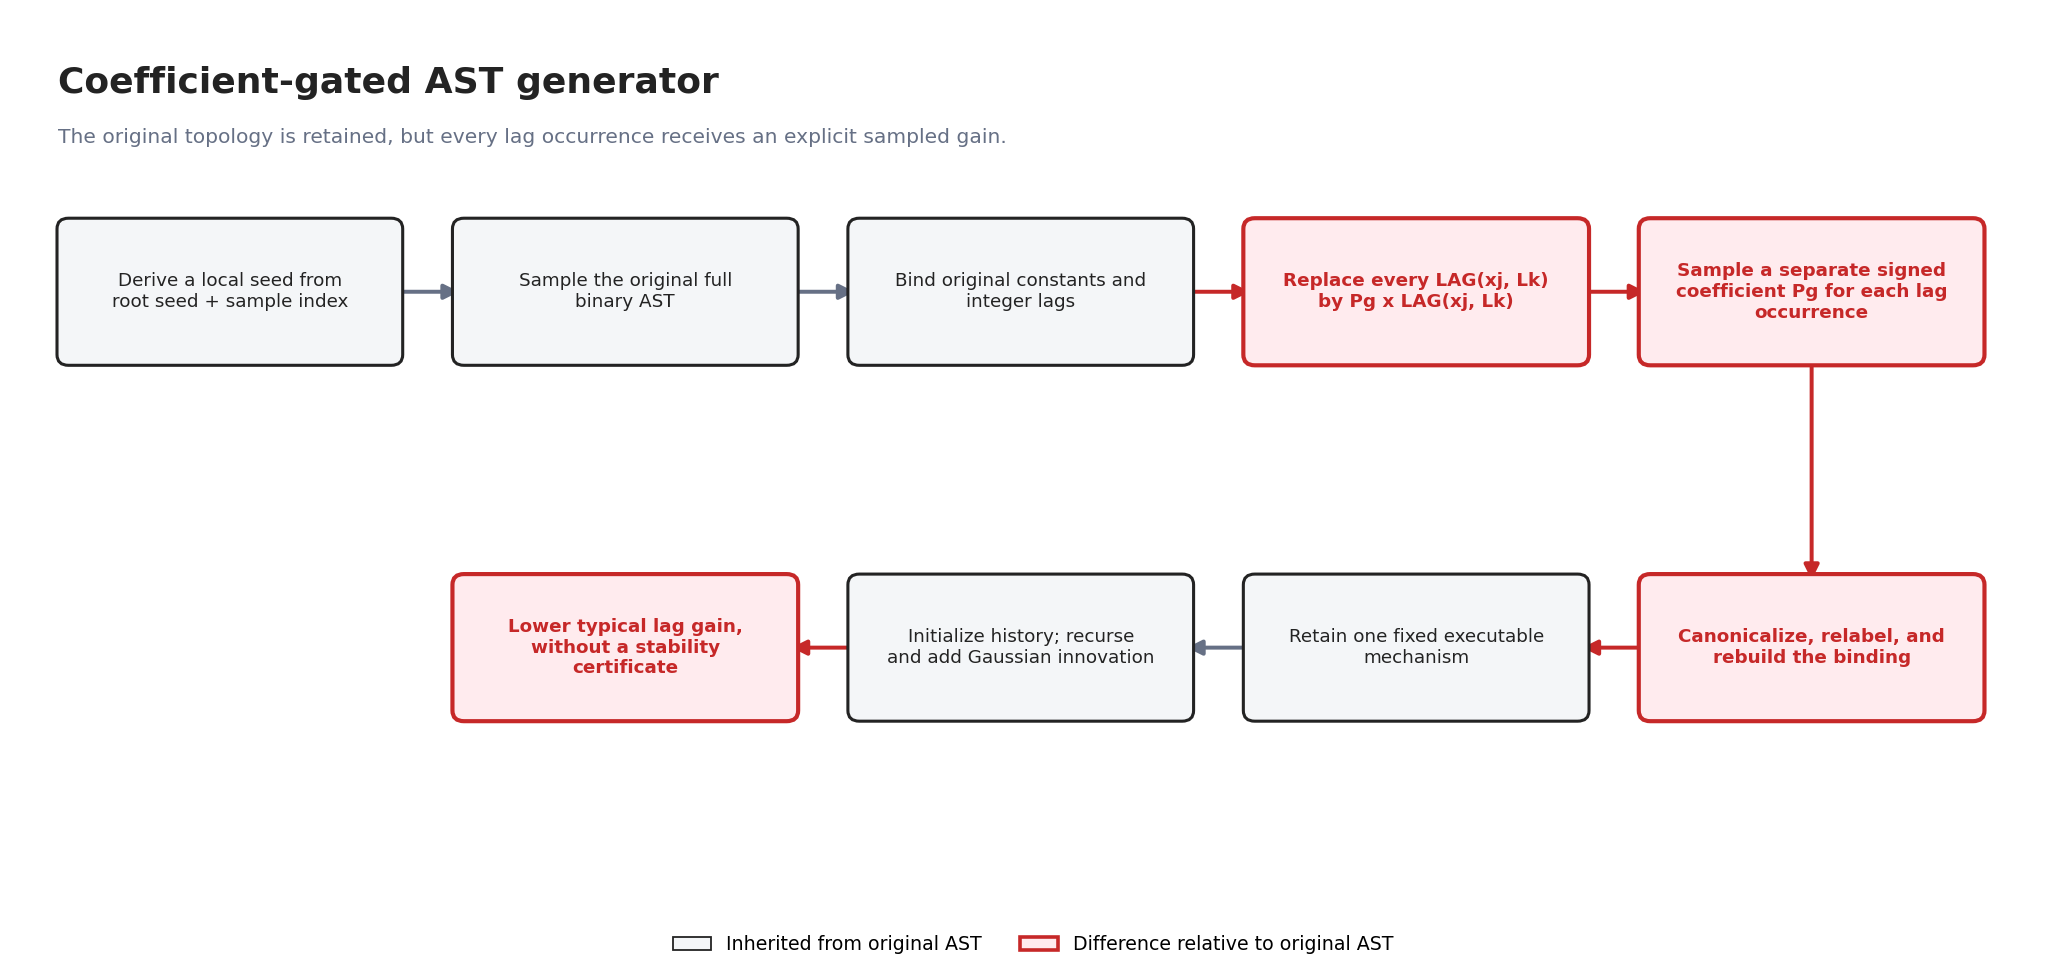

In [3]:
gated_steps = [
    {'name': 'seed', 'label': 'Derive a local seed from root seed + sample index', 'position': (1.7, 5.65)},
    {'name': 'tree', 'label': 'Sample the original full binary AST', 'position': (4.8, 5.65)},
    {'name': 'bind', 'label': 'Bind original constants and integer lags', 'position': (7.9, 5.65)},
    {'name': 'gate', 'label': 'Replace every LAG(xj, Lk) by Pg x LAG(xj, Lk)', 'position': (11.0, 5.65), 'changed': True},
    {'name': 'gatevalue', 'label': 'Sample a separate signed coefficient Pg for each lag occurrence', 'position': (14.1, 5.65), 'changed': True},
    {'name': 'relabel', 'label': 'Canonicalize, relabel, and rebuild the binding', 'position': (14.1, 2.65), 'changed': True},
    {'name': 'mechanism', 'label': 'Retain one fixed executable mechanism', 'position': (11.0, 2.65)},
    {'name': 'trajectory', 'label': 'Initialize history; recurse and add Gaussian innovation', 'position': (7.9, 2.65)},
    {'name': 'result', 'label': 'Lower typical lag gain, without a stability certificate', 'position': (4.8, 2.65), 'changed': True},
]
gated_edges = [
    ('seed', 'tree'), ('tree', 'bind'), ('bind', 'gate'), ('gate', 'gatevalue', True),
    ('gatevalue', 'relabel', True), ('relabel', 'mechanism', True),
    ('mechanism', 'trajectory'), ('trajectory', 'result', True),
]
fig = render_flowchart(
    'Coefficient-gated AST generator',
    'The original topology is retained, but every lag occurrence receives an explicit sampled gain.',
    gated_steps, gated_edges,
)
display(fig)
plt.close(fig)


**What this image shows.** Red identifies the local grammar transformation. The method weakens the implicit unit gain of lag leaves, but sums and products can still combine the coefficients into an unstable recurrence.

## 3. Linear stationary mechanisms by construction

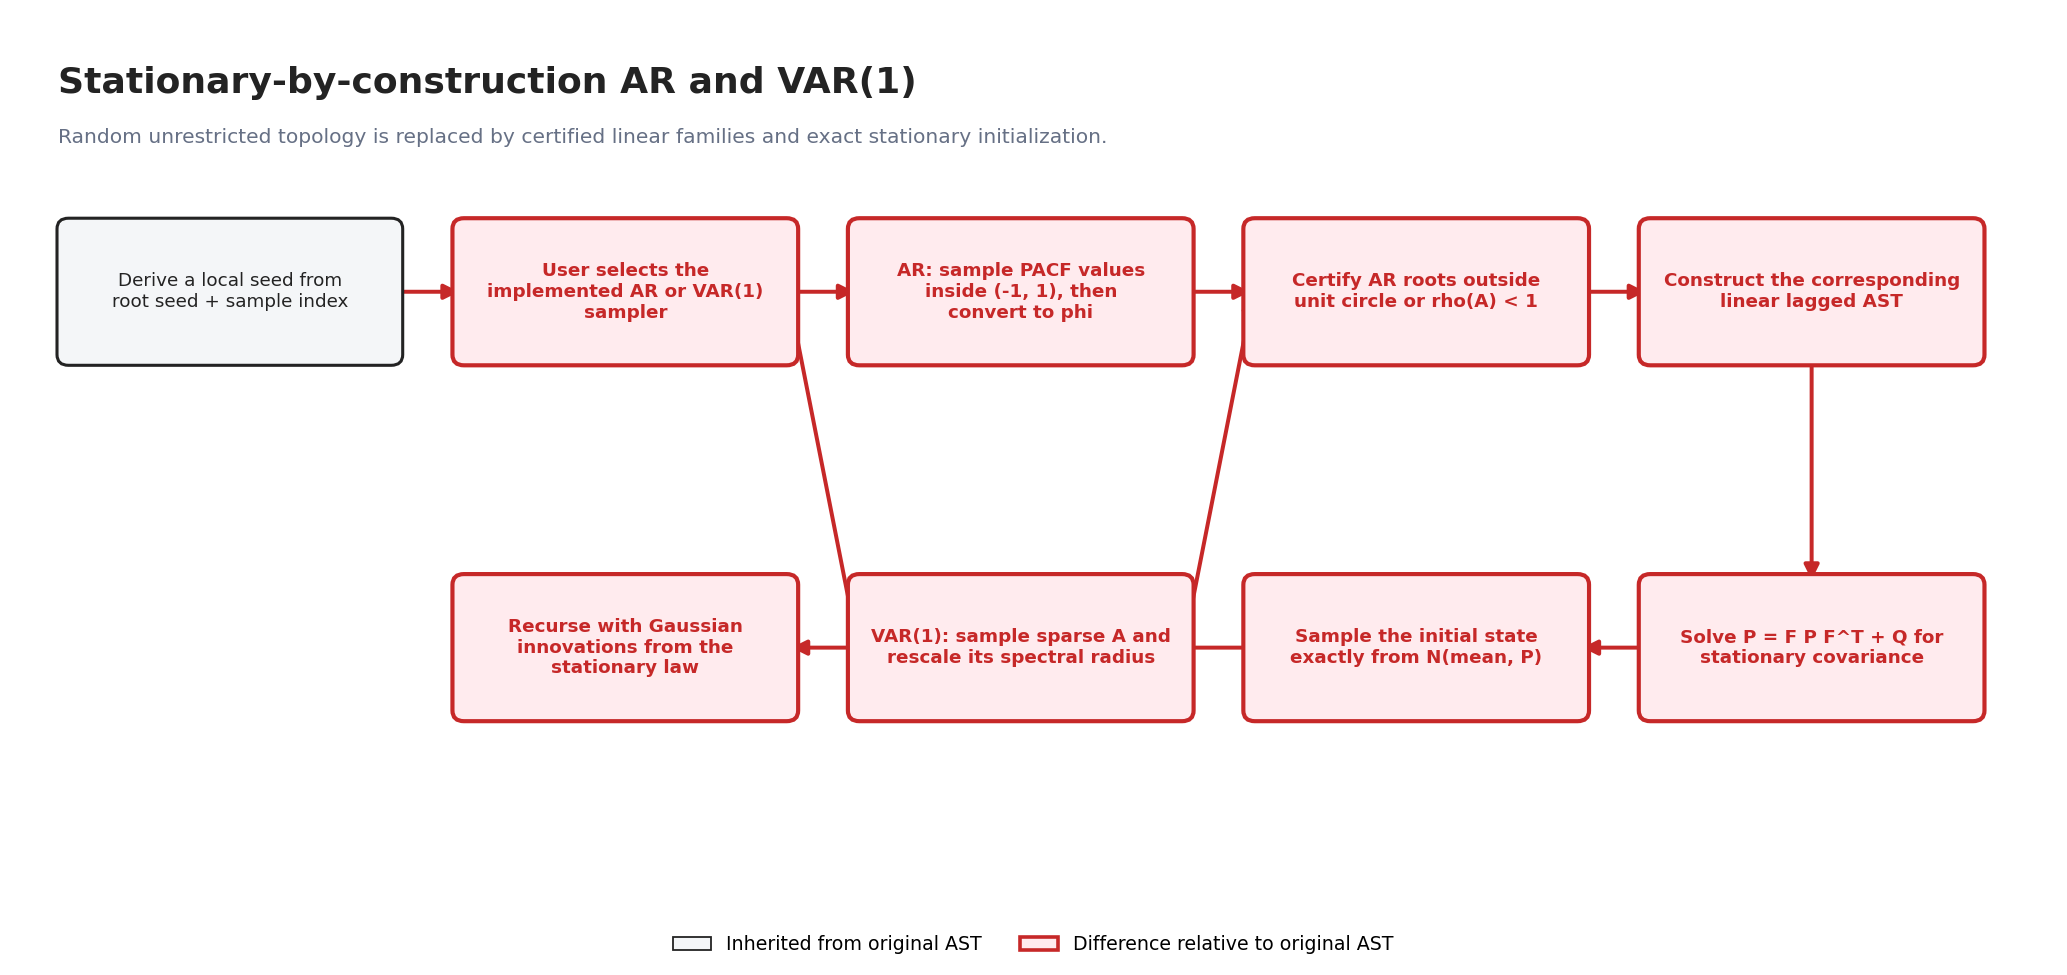

In [4]:
stationary_steps = [
    {'name': 'seed', 'label': 'Derive a local seed from root seed + sample index', 'position': (1.7, 5.65)},
    {'name': 'api', 'label': 'User selects the implemented AR or VAR(1) sampler', 'position': (4.8, 5.65), 'changed': True},
    {'name': 'ar', 'label': 'AR: sample PACF values inside (-1, 1), then convert to phi', 'position': (7.9, 5.65), 'changed': True},
    {'name': 'var', 'label': 'VAR(1): sample sparse A and rescale its spectral radius', 'position': (7.9, 2.65), 'changed': True},
    {'name': 'cert', 'label': 'Certify AR roots outside unit circle or rho(A) < 1', 'position': (11.0, 5.65), 'changed': True},
    {'name': 'linearast', 'label': 'Construct the corresponding linear lagged AST', 'position': (14.1, 5.65), 'changed': True},
    {'name': 'cov', 'label': 'Solve P = F P F^T + Q for stationary covariance', 'position': (14.1, 2.65), 'changed': True},
    {'name': 'initial', 'label': 'Sample the initial state exactly from N(mean, P)', 'position': (11.0, 2.65), 'changed': True},
    {'name': 'trajectory', 'label': 'Recurse with Gaussian innovations from the stationary law', 'position': (4.8, 2.65), 'changed': True},
]
stationary_edges = [
    ('seed', 'api', True), ('api', 'ar', True), ('api', 'var', True),
    ('ar', 'cert', True), ('var', 'cert', True), ('cert', 'linearast', True),
    ('linearast', 'cov', True), ('cov', 'initial', True),
    ('initial', 'trajectory', True),
]
fig = render_flowchart(
    'Stationary-by-construction AR and VAR(1)',
    'Random unrestricted topology is replaced by certified linear families and exact stationary initialization.',
    stationary_steps, stationary_edges,
)
display(fig)
plt.close(fig)


**What this image shows.** The stationary proposal changes the mechanism family itself. AR coefficients are obtained from admissible partial autocorrelations, whereas the VAR(1) matrix is rescaled to a spectral radius below one. Both paths construct a linear AST and use the Lyapunov covariance for initialization.

## 4. Nonlinear AST certified by contraction

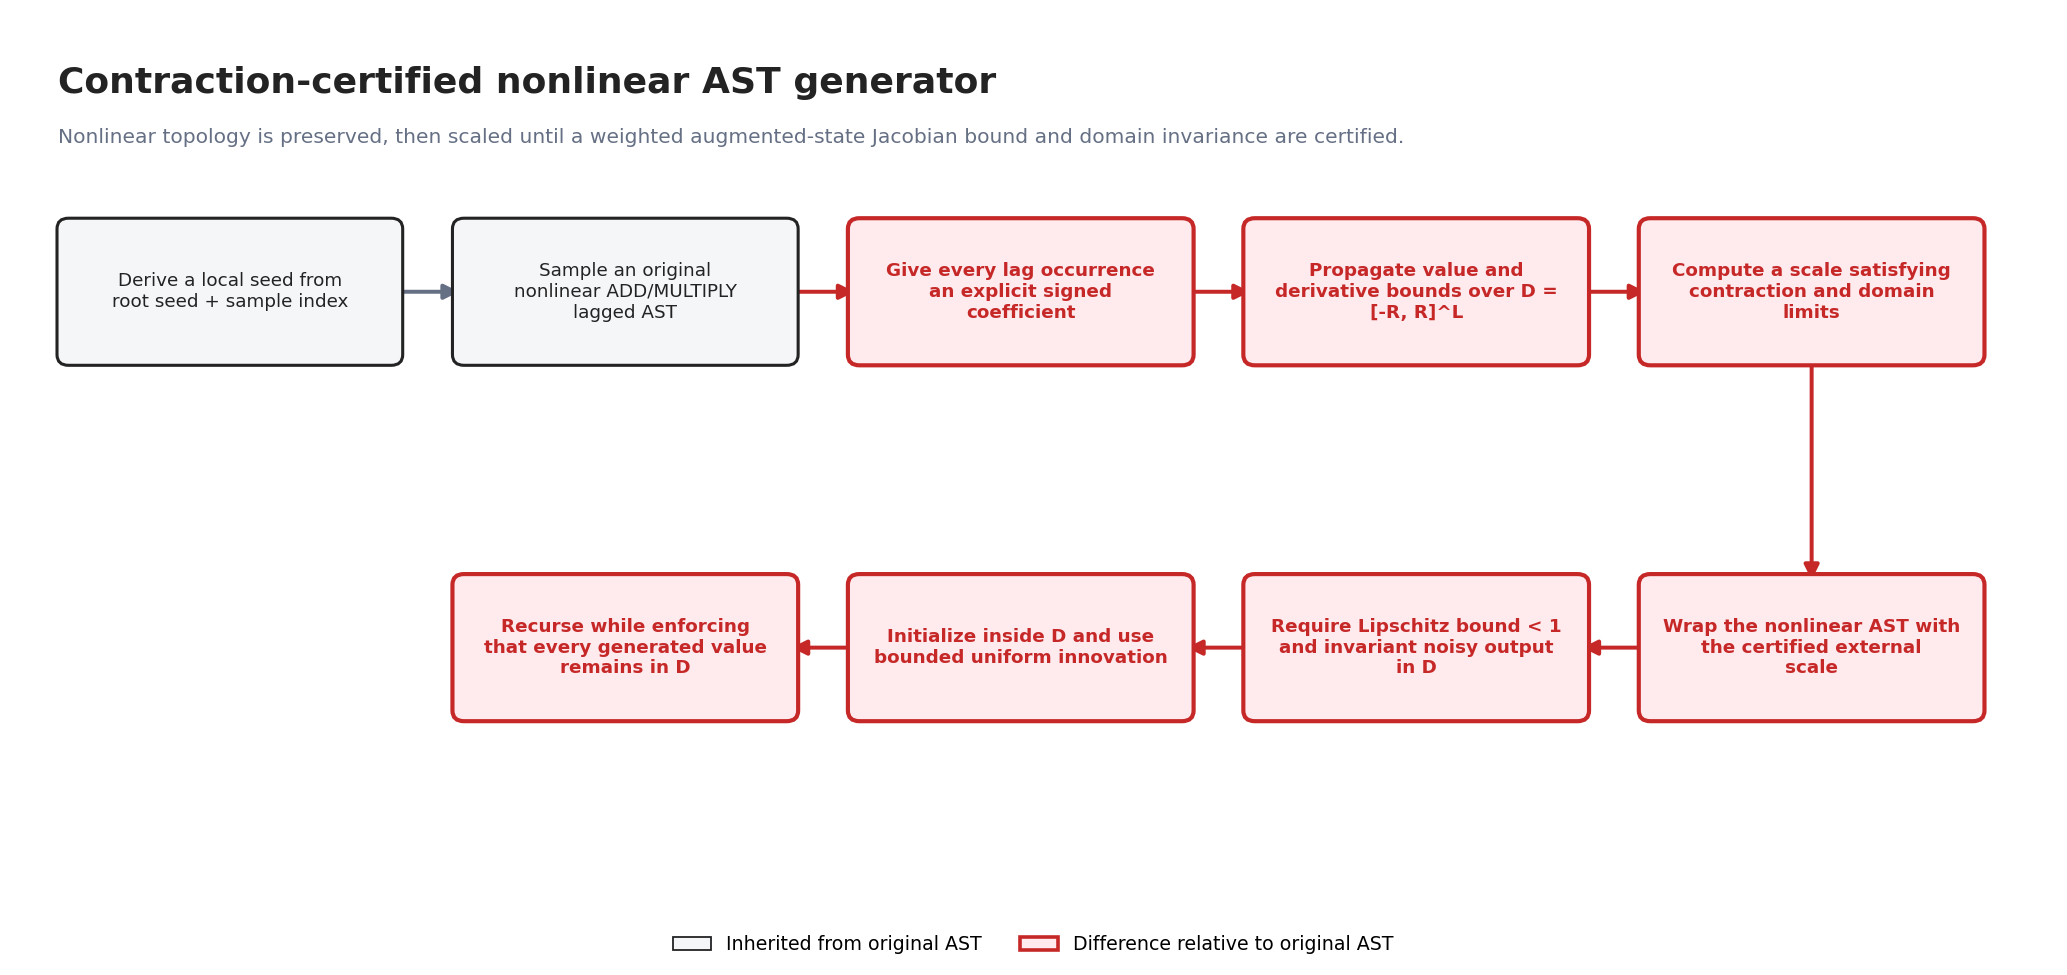

In [5]:
contraction_steps = [
    {'name': 'seed', 'label': 'Derive a local seed from root seed + sample index', 'position': (1.7, 5.65)},
    {'name': 'tree', 'label': 'Sample an original nonlinear ADD/MULTIPLY lagged AST', 'position': (4.8, 5.65)},
    {'name': 'gate', 'label': 'Give every lag occurrence an explicit signed coefficient', 'position': (7.9, 5.65), 'changed': True},
    {'name': 'bounds', 'label': 'Propagate value and derivative bounds over D = [-R, R]^L', 'position': (11.0, 5.65), 'changed': True},
    {'name': 'scale', 'label': 'Compute a scale satisfying contraction and domain limits', 'position': (14.1, 5.65), 'changed': True},
    {'name': 'wrap', 'label': 'Wrap the nonlinear AST with the certified external scale', 'position': (14.1, 2.65), 'changed': True},
    {'name': 'cert', 'label': 'Require Lipschitz bound < 1 and invariant noisy output in D', 'position': (11.0, 2.65), 'changed': True},
    {'name': 'noise', 'label': 'Initialize inside D and use bounded uniform innovation', 'position': (7.9, 2.65), 'changed': True},
    {'name': 'enforce', 'label': 'Recurse while enforcing that every generated value remains in D', 'position': (4.8, 2.65), 'changed': True},
]
contraction_edges = [
    ('seed', 'tree'), ('tree', 'gate', True), ('gate', 'bounds', True),
    ('bounds', 'scale', True), ('scale', 'wrap', True), ('wrap', 'cert', True),
    ('cert', 'noise', True), ('noise', 'enforce', True),
]
fig = render_flowchart(
    'Contraction-certified nonlinear AST generator',
    'Nonlinear topology is preserved, then scaled until a weighted augmented-state Jacobian bound and domain invariance are certified.',
    contraction_steps, contraction_edges,
)
display(fig)
plt.close(fig)


**What this image shows.** This method keeps nonlinear lag interactions but constrains their total sensitivity. The guarantee is tied to the declared bounded state domain and bounded innovation law; the red execution steps are therefore part of the certified generator rather than optional plotting checks.

## Complete notebook record

In [6]:
def git_output(*arguments: str) -> str | None:
    try:
        return subprocess.check_output(
            ['git', *arguments], cwd=PROJECT_ROOT, text=True,
            stderr=subprocess.DEVNULL,
        ).strip()
    except (subprocess.CalledProcessError, FileNotFoundError):
        return None


experiment_record = {
    'experiment_id': 'abstract_syntax_tree_007_generator_pseudocode_diagrams',
    'status': 'executed',
    'purpose': 'Create four directly comparable images of the implemented generator algorithms.',
    'configuration': {
        'layout': 'deterministic two-row flowcharts',
        'shared_color': BLACK,
        'difference_color': RED,
        'random_seed': None,
        'external_image_files': False,
    },
    'provenance': {
        'project_head': git_output('rev-parse', 'HEAD'),
        'python': sys.version,
        'platform': platform.platform(),
        'matplotlib': importlib.metadata.version('matplotlib'),
        'source_documents': [
            'experiments/abstract_syntax_tree/PSEUDOCODE.md',
            'experiments/abstract_syntax_tree/stability_mitigation/PSEUDOCODE.md',
            'experiments/abstract_syntax_tree/stationarity_by_construction/PSEUDOCODE.md',
            'experiments/abstract_syntax_tree/contraction_by_construction/PSEUDOCODE.md',
        ],
        'implementation': [
            'src/tsfmxai/generators/random_expression.py',
            'src/tsfmxai/generators/trajectory.py',
            'src/tsfmxai/generators/stationary.py',
            'src/tsfmxai/generators/contraction.py',
        ],
    },
    'scientific_summary': (
        'The diagrams distinguish unchanged random-AST operations from coefficient gating, '
        'linear stationarity-by-construction, and nonlinear contraction certification.'
    ),
    'reproduction_command': (
        r'.\.venv\Scripts\python.exe -m jupyter nbconvert --to notebook '
        r'--execute --inplace experiments\abstract_syntax_tree\7_generator_pseudocode_diagrams.ipynb'
    ),
}
print(json.dumps(experiment_record, indent=2, ensure_ascii=False))


{
  "experiment_id": "abstract_syntax_tree_007_generator_pseudocode_diagrams",
  "status": "executed",
  "purpose": "Create four directly comparable images of the implemented generator algorithms.",
  "configuration": {
    "layout": "deterministic two-row flowcharts",
    "shared_color": "#232323",
    "difference_color": "#c62828",
    "random_seed": null,
    "external_image_files": false
  },
  "provenance": {
    "project_head": "7e606837ff8a9c6c02895ef7dc331fcbf4ec4ae9",
    "python": "3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]",
    "platform": "Windows-10-10.0.19045-SP0",
    "matplotlib": "3.10.9",
    "source_documents": [
      "experiments/abstract_syntax_tree/PSEUDOCODE.md",
      "experiments/abstract_syntax_tree/stability_mitigation/PSEUDOCODE.md",
      "experiments/abstract_syntax_tree/stationarity_by_construction/PSEUDOCODE.md",
      "experiments/abstract_syntax_tree/contraction_by_construction/PSEUDOCODE.md"
    ],
    "implemen

**What this cell records.** It stores the deterministic visualization configuration, source documents, implementation files, software provenance, and reproduction command inside the executed notebook. The four images remain embedded in the notebook, so no duplicated image sidecars are needed.